In [1]:
import pandas as pd
# Install spacy
## -q is for "quiet". It removes logs
!pip install spacy -q
# Import spacy, if you don't have it --> !pip install spacy
import spacy
spacy.__version__
# Download model
!python -m spacy download en_core_web_sm -q
# Import english stop words
from spacy.lang.en.stop_words import STOP_WORDS

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
data = pd.read_csv('data.csv')

In [3]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['description'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

Tokens: ['Active', 'classic', 'boxers', '-', 'There', "'s", 'a', 'reason', 'why', 'our', 'boxers', 'are', 'a', 'cult', 'favorite', '-', 'they', 'keep', 'their', 'cool', ',', 'especially', 'in', 'sticky', 'situations', '.', 'The', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'up', 'minimal', 'space', 'in', 'a', 'travel', 'pack', '.', 'An', 'exposed', ',', 'brushed', 'waistband', 'offers', 'next', '-', 'to', '-', 'skin', 'softness', ',', 'five', '-', 'panel', 'construction', 'with', 'a', 'traditional', 'boxer', 'back', 'for', 'a', 'classic', 'fit', ',', 'and', 'a', 'functional', 'fly', '.', 'Made', 'of', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'with', 'moisture', '-', 'wicking', 'performance', '.', 'Inseam', '(', 'size', 'M', ')', 'is', '4', '1/2', '"', '.', 'Recyclable', 'through', 'the', 'Common', 'Threads', 'Recycling', 'Program.<br><br><b', '>', 'Details:</b><ul', '>', '<', 'li>"Silky', 'Capilene', '1', 'fabric', 'is', 'ultralight', ',', 'breathabl

In [4]:
# Print stop words
print(STOP_WORDS)

{'whereby', 'namely', 'here', 'thereby', 'while', 'perhaps', 'empty', 'everyone', 'wherein', 'after', 'being', 'whoever', 'elsewhere', 'below', 're', 'beside', 'should', 'already', 'used', 'so', 'however', 'had', 'seem', 'other', 'even', 'along', 'is', 'besides', 'over', "'s", 'with', 'his', 'seems', 'something', 'our', 'your', 'done', 'unless', 'more', 'again', 'latter', 'could', '’ve', 'show', 'the', '‘re', 'same', 'since', 'eight', 'anything', 'him', 'when', 'indeed', 'and', 'six', 'for', 'around', 'mine', 'move', 'becoming', 'whereafter', 'few', "'re", 'than', 'into', "'ve", 'much', 'down', 'make', 'what', 'anyone', 'neither', 'does', 'everything', 'seeming', 'bottom', 'a', 'regarding', 'three', 'made', 'each', 'alone', 'former', 'who', 'once', 'serious', 'ca', 'towards', 'due', 'top', "'d", 'can', 'might', 'only', 'beyond', 'ours', 'anyhow', 'cannot', 'mostly', 'if', 'within', 'where', 'do', 'of', 'up', 'this', 'seemed', 'back', "'ll", '’re', 'always', 'never', 'least', 'some', 'g

In [5]:
# Install wordcloud if necessary
# !pip install wordcloud -q

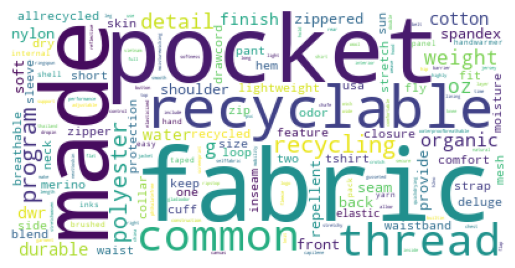

In [8]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud

text = " ".join(data['description'].astype(str))
text = re.sub(r"<[^>]+>", " ", text)
text = re.sub(r"[!\"#$%&()*+,-./:;<=>?@[\\\]^_`{|}~]+", "", text).lower() # lowercase

# Create lemmatization
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]

cloud = wordcloud.WordCloud(collocations=False, background_color="white", colormap="viridis").generate(text) # élimine les paires de mots

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

In [9]:
from collections import Counter; Counter(text.split()).most_common(30)

[('and', 2948),
 ('the', 2634),
 ('a', 1803),
 ('with', 1461),
 ('for', 1091),
 ('in', 953),
 ('fabric', 889),
 ('made', 805),
 ('through', 726),
 ('to', 723),
 ('recyclable', 704),
 ('common', 684),
 ('threads', 684),
 ('recycling', 684),
 ('program', 683),
 ('of', 642),
 ('is', 627),
 ('polyester', 591),
 ('100', 548),
 ('details', 536),
 ('weight', 520),
 ('g', 493),
 ('oz', 493),
 ('organic', 449),
 ('pockets', 414),
 ('on', 394),
 ('pocket', 393),
 ('durable', 377),
 ('from', 373),
 ('cotton', 372)]

La taille d’un mot dépend de sa fréquence dans le texte : plus il est gros, plus il apparaît souvent. La position, l’orientation et la couleur sont aléatoires et n’ont aucune signification. dwr signifie Durable Water Repellent. g pourrait mesurer le poids. 

Prochaines étapes 
puis data mining avec tf idf
retirer le bruit

In [10]:
# import displacy
from spacy import displacy

# render displacy
displacy.render(doc, style='dep', jupyter=True,options={'distance': 70})